# Breast Cancer Classification using TensorFlow - Practice project


## Business Context

A diagnostic lab processes hundreds of breast tissue biopsies every week. Each sample yields 30 numeric measurements — cell radius, texture, perimeter, smoothness, and more. A pathologist manually reviews every slide, which is slow, expensive, and subject to fatigue.

**Your job:** Build a deep neural network that classifies biopsies as malignant or benign from the 30 measurements alone. This isn't replacing pathologists — it's giving them a second opinion. A false negative (missing cancer) has life-or-death consequences. A false positive means an unnecessary follow-up biopsy. Your model needs high recall AND precision.


# Business Context -- What are we solving?

Before any code: what's the cost of getting this wrong

- **False negative (missed cancer):** Patient sent home, cancer progresses. Catastrophic.
- **False positive:** Unnecessary biopsy — stressful, expensive (~₹15,000), but not life-threatening.

This means **recall > precision** — we'd rather flag 10 benign cases for follow-up than miss 1 malignant one.

The dataset: 569 biopsies from the University of Wisconsin. 30 features extracted from digitised images of fine needle aspirates. 

Each labelled malignant (0) or benign (1).

Benign and Malignant are terms commonly used to describe tumors or growths

- Benign - Non Cancerous
- Malignant - Cancerous

In [2]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Step 2 : Load data

In [3]:
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names      # 30 features
target_names =  data.target_names       # 0 = malignant, 1 = benign

print("Feature Shape",X.shape)
print("Target shape",y.shape)
print(f"Malignant: {(y==0).sum()} ({(y==0).mean():.1%})" )
print(f"Benign:    {(y==1).sum()} ({(y==1).mean():.1%})" )

# putting the output in form of %

Feature Shape (569, 30)
Target shape (569,)
Malignant: 212 (37.3%)
Benign:    357 (62.7%)


In [4]:
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

In [5]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [6]:
# Compare Means : Malignant vs Benign

df.groupby('target')[['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'mean compactness']].mean().round(2)

,mean radius,mean perimeter,mean area,mean concavity,mean concave points,mean compactness
target,,,,,,
0,17.46,115.37,978.38,0.16,0.09,0.15
1,12.15,78.08,462.79,0.05,0.03,0.08


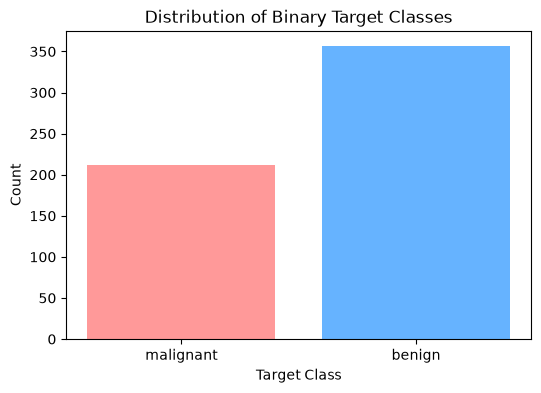

In [7]:
# Plot the bar chart of Target columns

classes, counts = np.unique(y, return_counts=True)

# create a bar chart
plt.figure(figsize=(6,4))
plt.bar(target_names, counts, color=['#ff9999', '#66b3ff'])

# Add titles and labels
plt.title('Distribution of Binary Target Classes')
plt.xlabel('Target Class')
plt.ylabel('Count')

plt.show()

# Observation from the data

- 569 Samples & 30 features 
- 37.3% Malignant, 62.7% Benign - Mild class imbalance
- Malignant tumors are larger in mean values - feature which carry a signal
- All features are numeric -> Need for Scaling (StandardScaler)

# Step 3: Correlation Check

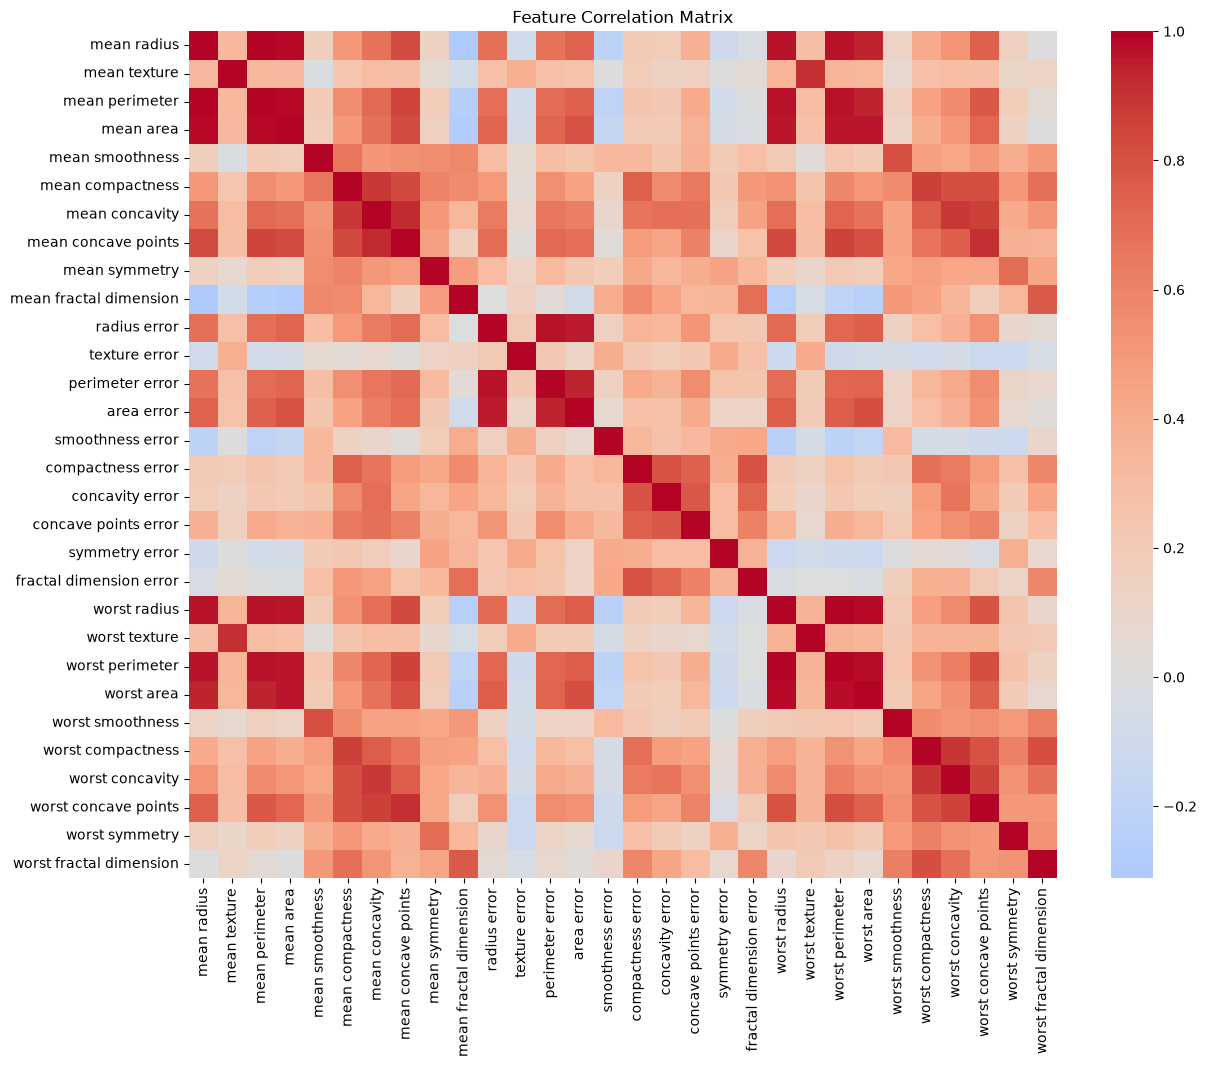

In [8]:
plt.figure(figsize=(14,11))

correlation_matrix = df.drop(columns="target").corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)
plt.title("Feature Correlation Matrix")
plt.show()

In [9]:
# this shows several feature co-relate with each other because radius, perimeter and area describe related tumor characteristics.


# Step 4 : Prepare the data

3 operations - Train/test split, standard scaling, starify and no encoding(all numeric)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=42, stratify=y)

print(f"train data: {X_train.shape} | test data: {X_test.shape}")
print(f"Malignant rate in train data: {y_train.mean():.1%}")

train data: (426, 30) | test data: (143, 30)
Malignant rate in train data: 62.7%


In [11]:
# Standard Scaling

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled =  scaler.transform(X_test)

# After scaling Mean=0 & STD=1
print(f"Train mean: {X_train_scaled.mean():.4f} | STD: {X_train_scaled.std():.4f}")


Train mean: 0.0000 | STD: 1.0000


# Step 5: Build the model - Sequential API

In [13]:
model = Sequential([
    Dense(32,activation='relu',input_shape=(X_train.shape[1],), name='hidden_1'),
    Dropout(0.3, name='dropout_1'),   # dropout randomly sets 30% of the previous layer’s outputs to zero.
    Dense(8,activation='relu',input_shape=(X_train.shape[1],), name='hidden_2'),
    Dense(1, activation='sigmoid', name='output')
])

#  layer 1 - 30 inputs + 32 neurons + 32 bias = 992
# layer 2  - 8 neurons * 1 bias + 1 biases    = 264
# output layer - 8 neurons * 1 bias + 1 bias =    9
model.summary()

c:\Desktop\Desktop\Microsoft_AI_Engineering\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,265 (4.94 KB)

 Trainable params: 1,265 (4.94 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Compile model

model.compile(
    optimizer='adam',
    loss = 'binary_crossentropy',   # as this is classification
    metrics=['accuracy']
)

In [15]:
# Train the Model 

history = model.fit(
    X_train, y_train,
    epochs=80,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/80
11/11 ━━━━━━━━━━━━━━━━━━━━ 34s 57ms/step - accuracy: 0.4824 - loss: 18.5051 - val_accuracy: 0.6279 - val_loss: 5.3020
Epoch 2/80
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5412 - loss: 13.1960 - val_accuracy: 0.6279 - val_loss: 11.3092
Epoch 3/80
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5324 - loss: 12.1188 - val_accuracy: 0.6279 - val_loss: 11.0746
Epoch 4/80
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5353 - loss: 9.2882 - val_accuracy: 0.6395 - val_loss: 7.2505
Epoch 5/80
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5441 - loss: 7.3443 - val_accuracy: 0.6628 - val_loss: 4.9554
Epoch 6/80
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5588 - loss: 6.1900 - val_accuracy: 0.7093 - val_loss: 3.3095
Epoch 7/80
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5500 - loss: 5.0700 - val_accuracy: 0.7093 - val_loss: 3.3686
Epoch 8/80
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6235 - loss: 4.0392 - val_accuracy: 0.70

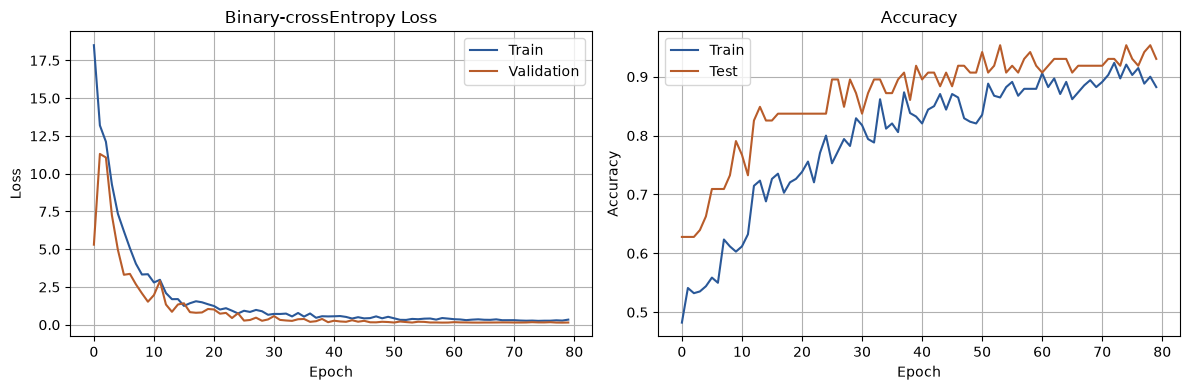

In [19]:
# Plot training curves

fig, (ax1,ax2) = plt.subplots(1,2, figsize=(12,4))

ax1.plot(history.history['loss'], label='Train', color='#2a5898')
ax1.plot(history.history['val_loss'], label='Validation', color='#b85c2a')
ax1.set_title("Binary-crossEntropy Loss")
ax1.set_ylabel('Loss')
ax1.set_xlabel('Epoch')
ax1.legend()
ax1.grid()

ax2.plot(history.history['accuracy'], label='Train', color='#2a5898')
ax2.plot(history.history['val_accuracy'], label='Test', color='#b85c2a')
ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid()

plt.tight_layout();
plt.show()


In [ ]:
# Observations from the above graph

# For Binary-crossentroy loss - As the Epoch increase both training and validation loss decreases
# For accuracy -- As the Epoch increase the Accuracy also increased

# Step 6 - Evaluate 


In [20]:
# test set evalution

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f} ")
print(f"Test loss: {test_loss:.4f}")

Test Accuracy: 0.9301 
Test loss: 0.2038


In [ ]:
# Classificaiton report 
y_pred_prob = model.predict(X_test,verbose=0).flatten()
y_pred  = (y_pred_prob > 0.5).astype(int)


In [21]:
X_test

array([[1.275e+01, 1.670e+01, 8.251e+01, ..., 8.045e-02, 3.071e-01,
        8.557e-02],
       [1.799e+01, 2.066e+01, 1.178e+02, ..., 1.974e-01, 3.060e-01,
        8.503e-02],
       [1.496e+01, 1.910e+01, 9.703e+01, ..., 1.489e-01, 2.962e-01,
        8.472e-02],
       ...,
       [1.170e+01, 1.911e+01, 7.433e+01, ..., 5.741e-02, 3.487e-01,
        6.958e-02],
       [1.450e+01, 1.089e+01, 9.428e+01, ..., 1.221e-01, 2.889e-01,
        8.006e-02],
       [1.218e+01, 1.784e+01, 7.779e+01, ..., 5.882e-02, 2.227e-01,
        7.376e-02]], shape=(143, 30))